CRS: EPSG:3857
Dimensions: 9590 8748
Number of bands: 4
Color interpretation: (<ColorInterp.red: 3>, <ColorInterp.green: 4>, <ColorInterp.blue: 5>, <ColorInterp.alpha: 6>)
Bounds: BoundingBox(left=-13624234.2822, bottom=4535201.5062, right=-13587216.0287, top=4568969.5648)


Skipping field label_coords: unsupported OGR type: 3



Image array: (3192, 3500, 4)
RGB minimum: 0
RGB maximum: 255
Geographic bounds: [[37.68627646982084, -122.38857890125416], [37.925944745744665, -122.05603827214955]]

HOLC features: 120
HOLC original CRS: EPSG:4326
HOLC grades: {'B': 46, 'C': 41, 'D': 20, 'A': 12}


/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore



Map exported successfully:
/Users/sophiameyers/Documents/GitHub/30-day-mapping/outputs/Oakland_1937_HOLC_Interactive.html



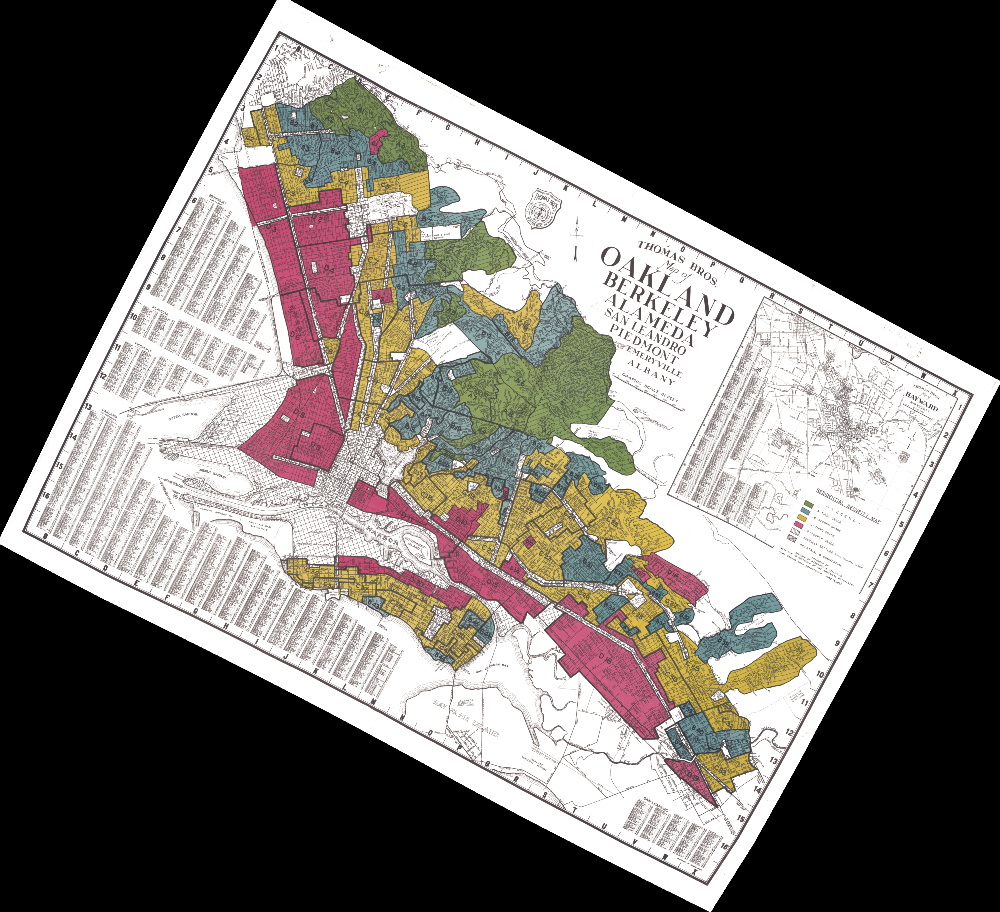

In [3]:
# ============================================================
# OAKLAND 1937 — GEORECTIFIED TIFF + HOLC GEOJSON
# SIMPLE FOLIUM IMAGE OVERLAY
# ============================================================

import os
import numpy as np
import rasterio
import geopandas as gpd
import folium

from rasterio.enums import Resampling
from rasterio.warp import transform_bounds
from folium.raster_layers import ImageOverlay
from folium.features import GeoJsonTooltip, GeoJsonPopup


# ------------------------------------------------------------
# 1. FILE PATHS
# ------------------------------------------------------------

basemap_path = (
    "/Users/sophiameyers/Documents/GitHub/"
    "30-day-mapping/data/CA_Oakland_1937.tif"
)

holc_path = (
    "/Users/sophiameyers/Documents/GitHub/"
    "30-day-mapping/data/geojson.json"
)

output_dir = (
    "/Users/sophiameyers/Documents/GitHub/"
    "30-day-mapping/outputs"
)

os.makedirs(output_dir, exist_ok=True)


# ------------------------------------------------------------
# 2. READ ORIGINAL TIFF
# ------------------------------------------------------------

with rasterio.open(basemap_path) as src:

    print("CRS:", src.crs)
    print("Dimensions:", src.width, src.height)
    print("Number of bands:", src.count)
    print("Color interpretation:", src.colorinterp)
    print("Bounds:", src.bounds)

    # Resize for browser display without changing geographic extent.
    max_dimension = 3500

    scale = min(
        1,
        max_dimension / max(src.width, src.height)
    )

    new_width = max(1, int(src.width * scale))
    new_height = max(1, int(src.height * scale))

    # Read the first three bands directly.
    rgb = src.read(
        [1, 2, 3],
        out_shape=(3, new_height, new_width),
        resampling=Resampling.bilinear
    )

    # Convert to standard 8-bit image values.
    rgb = np.nan_to_num(rgb, nan=0)
    rgb = np.clip(rgb, 0, 255).astype(np.uint8)

    # Transform the original raster bounds to latitude/longitude.
    west, south, east, north = transform_bounds(
        src.crs,
        "EPSG:4326",
        *src.bounds,
        densify_pts=21
    )

# Convert to image array: rows, columns, RGB.
image = np.moveaxis(rgb, 0, -1)

# Make all pixels opaque for this initial rendering test.
alpha = np.full(
    (new_height, new_width),
    255,
    dtype=np.uint8
)

rgba = np.dstack((image, alpha))

image_bounds = [
    [south, west],
    [north, east]
]

print("\nImage array:", rgba.shape)
print("RGB minimum:", rgb.min())
print("RGB maximum:", rgb.max())
print("Geographic bounds:", image_bounds)


# ------------------------------------------------------------
# 3. LOAD HOLC GEOJSON
# ------------------------------------------------------------

holc = gpd.read_file(holc_path)

print("\nHOLC features:", len(holc))
print("HOLC original CRS:", holc.crs)

# Set CRS only if missing, using the known GeoJSON coordinates.
if holc.crs is None:
    holc = holc.set_crs("EPSG:4326")

holc = holc.to_crs("EPSG:4326")

holc["grade"] = holc["grade"].astype(str).str.upper()

print("HOLC grades:", holc["grade"].value_counts().to_dict())


# ------------------------------------------------------------
# 4. HOLC COLORS
# ------------------------------------------------------------

grade_colors = {
    "A": "#4A9B72",
    "B": "#6C8EBF",
    "C": "#E6B84A",
    "D": "#C85A50"
}


# ------------------------------------------------------------
# 5. CREATE MAP
# ------------------------------------------------------------

center_lat = (south + north) / 2
center_lon = (west + east) / 2

m = folium.Map(
    location=[center_lat, center_lon],
    zoom_start=14,
    tiles="CartoDB positron",
    control_scale=True
)


# ------------------------------------------------------------
# 6. ADD ORIGINAL 1937 TIFF
# ------------------------------------------------------------

ImageOverlay(
    image=rgba,
    bounds=image_bounds,
    opacity=1,
    interactive=False,
    origin="upper",
    pixelated=False,
    name="1937 Oakland Historical Map",
    zindex=2
).add_to(m)


# ------------------------------------------------------------
# 7. ADD HOLC POLYGONS
# ------------------------------------------------------------

def style_holc(feature):

    grade = feature["properties"].get("grade", "")

    return {
        "fillColor": grade_colors.get(grade, "#999999"),
        "color": "#292929",
        "weight": 1.2,
        "opacity": 0.9,
        "fillOpacity": 0.30
    }


def highlight_holc(feature):

    return {
        "color": "#FFFFFF",
        "weight": 3,
        "fillOpacity": 0.60
    }


holc_fields = [
    field for field in ["label", "grade", "area_id"]
    if field in holc.columns
]

holc_aliases = {
    "label": "Historical Area",
    "grade": "HOLC Grade",
    "area_id": "Area ID"
}

holc_layer = folium.GeoJson(
    data=holc.to_json(),
    name="HOLC Historical Boundaries",
    style_function=style_holc,
    highlight_function=highlight_holc,

    tooltip=GeoJsonTooltip(
        fields=holc_fields,
        aliases=[holc_aliases.get(f, f) for f in holc_fields]
    ),

    popup=GeoJsonPopup(
        fields=holc_fields,
        aliases=[holc_aliases.get(f, f) for f in holc_fields]
    )
)

holc_layer.add_to(m)


# ------------------------------------------------------------
# 8. LEGEND
# ------------------------------------------------------------

legend = """
<div style="
    position: fixed;
    bottom: 35px;
    right: 25px;
    z-index: 9999;
    background: white;
    padding: 12px 16px;
    border: 1px solid #777;
    border-radius: 4px;
    font-family: Arial;
    font-size: 13px;
">
<b>HOLC Security Grades</b>
"""

for grade, color in grade_colors.items():

    legend += f"""
    <div style="margin-top:5px;">
        <span style="
            display:inline-block;
            width:14px;
            height:14px;
            background:{color};
            margin-right:7px;
        "></span>
        Grade {grade}
    </div>
    """

legend += "</div>"

m.get_root().html.add_child(
    folium.Element(legend)
)


# ------------------------------------------------------------
# 9. LAYER CONTROL
# ------------------------------------------------------------

folium.LayerControl(
    collapsed=False
).add_to(m)


# ------------------------------------------------------------
# 10. ZOOM TO IMAGE
# ------------------------------------------------------------

m.fit_bounds(image_bounds)


# ------------------------------------------------------------
# 11. SAVE HTML
# ------------------------------------------------------------

output_path = os.path.join(
    output_dir,
    "Oakland_1937_HOLC_Interactive.html"
)

m.save(output_path)

print("\nMap exported successfully:")
print(output_path)

m

In [4]:
import os
import re
import glob
import zipfile
import requests
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import folium

from io import BytesIO
from affine import Affine
from rasterio.warp import calculate_default_transform, reproject, transform_bounds, Resampling
from rasterio.transform import array_bounds
from folium.raster_layers import ImageOverlay
from folium.features import GeoJsonTooltip

In [5]:
# ============================================================
# PATHS
# ============================================================

basemap_path = (
    "/Users/sophiameyers/Documents/GitHub/"
    "30-day-mapping/data/CA_Oakland_1937.tif"
)

holc_path = (
    "/Users/sophiameyers/Documents/GitHub/"
    "30-day-mapping/data/geojson.json"
)

output_dir = (
    "/Users/sophiameyers/Documents/GitHub/"
    "30-day-mapping/outputs"
)

os.makedirs(output_dir, exist_ok=True)


# ============================================================
# CENSUS API KEY
# ============================================================

census_key = os.environ.get("CENSUS_API_KEY")

if not census_key:
    renviron_path = os.path.expanduser("~/.Renviron")

    if os.path.exists(renviron_path):
        with open(renviron_path) as f:
            for line in f:
                match = re.match(
                    r'^\s*CENSUS_API_KEY\s*=\s*"?([^"\n]+)"?',
                    line
                )
                if match:
                    census_key = match.group(1).strip()
                    break

if not census_key:
    raise ValueError(
        "Census API key not found. Set CENSUS_API_KEY "
        "as an environment variable or in ~/.Renviron."
    )

print("Census API key found.")

Census API key found.


In [6]:
# ============================================================
# LOAD AND STRAIGHTEN HISTORICAL TIFF
# ============================================================

target_crs = "EPSG:3857"

with rasterio.open(basemap_path) as src:

    print("Original CRS:", src.crs)
    print("Original dimensions:", src.width, src.height)
    print("Original transform:", src.transform)

    if src.crs is None:
        raise ValueError("The TIFF has no CRS defined.")

    # Calculate a north-up output grid.
    dst_transform, dst_width, dst_height = (
        calculate_default_transform(
            src.crs,
            target_crs,
            src.width,
            src.height,
            *src.bounds
        )
    )

    # Reduce image size for browser performance.
    max_dimension = 3500

    scale = min(
        1,
        max_dimension / max(dst_width, dst_height)
    )

    new_width = max(1, int(dst_width * scale))
    new_height = max(1, int(dst_height * scale))

    dst_transform = dst_transform * Affine.scale(
        dst_width / new_width,
        dst_height / new_height
    )

    # Allocate destination RGB image.
    rgb_mercator = np.zeros(
        (3, new_height, new_width),
        dtype=np.uint8
    )

    # Reproject each RGB band.
    for band in range(1, 4):

        source_band = src.read(band)

        reproject(
            source=source_band,
            destination=rgb_mercator[band - 1],

            src_transform=src.transform,
            src_crs=src.crs,

            dst_transform=dst_transform,
            dst_crs=target_crs,

            resampling=Resampling.bilinear
        )

# Convert to image array.
rgb_image = np.moveaxis(
    rgb_mercator,
    0,
    -1
)

# Make an opaque RGBA image.
alpha = np.full(
    (new_height, new_width),
    255,
    dtype=np.uint8
)

rgba = np.dstack([
    rgb_image,
    alpha
])

# Get projected image bounds.
left, bottom, right, top = array_bounds(
    new_height,
    new_width,
    dst_transform
)

# Convert bounds to geographic coordinates.
west, south, east, north = transform_bounds(
    target_crs,
    "EPSG:4326",
    left,
    bottom,
    right,
    top,
    densify_pts=21
)

image_bounds = [
    [south, west],
    [north, east]
]

print("North-up image dimensions:", rgba.shape)
print("Image bounds:", image_bounds)

Original CRS: EPSG:3857
Original dimensions: 9590 8748
Original transform: | 3.86, 0.00,-13624234.28|
| 0.00,-3.86, 4568969.56|
| 0.00, 0.00, 1.00|


/var/folders/3t/qsrrrg8559d3byzjqfp_ybs40000gn/T/ipykernel_4557/1254855578.py:52: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  source_band = src.read(band)
/var/folders/3t/qsrrrg8559d3byzjqfp_ybs40000gn/T/ipykernel_4557/1254855578.py:52: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  source_band = src.read(band)
/var/folders/3t/qsrrrg8559d3byzjqfp_ybs40000gn/T/ipykernel_4557/1254855578.py:52: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  source_band = src.read(band)


North-up image dimensions: (3192, 3500, 4)
Image bounds: [[37.68627646982084, -122.38857890125416], [37.925944745744665, -122.05603827214955]]


In [7]:
# ============================================================
# LOAD HOLC GEOJSON
# ============================================================

holc = gpd.read_file(holc_path)

if holc.crs is None:
    holc = holc.set_crs("EPSG:4326")

holc = holc.to_crs("EPSG:4326")

holc = holc.reset_index(drop=True)

holc["holc_id"] = np.arange(len(holc))

holc["grade"] = (
    holc["grade"]
    .astype(str)
    .str.upper()
)

holc = holc[
    holc["grade"].isin(["A", "B", "C", "D"])
].copy()

# Ensure geometries are valid.
holc.geometry = holc.geometry.make_valid()

# Make a label if needed.
if "label" not in holc.columns:
    holc["label"] = (
        "HOLC Area " + holc["holc_id"].astype(str)
    )

holc["label"] = holc["label"].fillna(
    "HOLC Area " + holc["holc_id"].astype(str)
)

print("HOLC areas:", len(holc))
print(holc["grade"].value_counts())

Skipping field label_coords: unsupported OGR type: 3


HOLC areas: 119
grade
B    46
C    41
D    20
A    12
Name: count, dtype: int64


In [15]:
import requests
import pandas as pd
from getpass import getpass

CENSUS_KEY = getpass("Enter your Census API key: ").strip()

url = "https://api.census.gov/data/2024/acs/acs5"

params = {
    "get": "NAME,B03002_001E,B19013_001E",
    "for": "tract:*",
    "in": "state:06 county:001",
    "key": CENSUS_KEY
}

response = requests.get(
    url,
    params=params,
    timeout=90,
    allow_redirects=False
)

print("Status:", response.status_code)
print("Content type:", response.headers.get("Content-Type"))
print("Redirect:", response.headers.get("Location"))

if response.status_code == 200 and "json" in response.headers.get("Content-Type", "").lower():
    data = response.json()
    test_df = pd.DataFrame(data[1:], columns=data[0])
    print("SUCCESS — downloaded", len(test_df), "Alameda County census tracts")
    display(test_df.head())
else:
    print("Census API rejected the request:")
    print(response.text[:1000])

Enter your Census API key:  ········


Status: 200
Content type: application/json;charset=utf-8
Redirect: None
SUCCESS — downloaded 379 Alameda County census tracts


,NAME,B03002_001E,B19013_001E,state,county,tract
0,Census Tract 4001; Alameda County; California,3132,250001,06,001,400100
1,Census Tract 4002; Alameda County; California,2203,208438,06,001,400200
2,Census Tract 4003; Alameda County; California,5990,176618,06,001,400300
3,Census Tract 4004; Alameda County; California,4399,165134,06,001,400400
4,Census Tract 4005; Alameda County; California,3579,96641,06,001,400500


In [16]:
import requests
import pandas as pd

# ACS 2024 5-year estimates
url = "https://api.census.gov/data/2024/acs/acs5"

variables = [
    "B03002_001E",  # Total population
    "B03002_003E",  # White, non-Hispanic
    "B03002_004E",  # Black, non-Hispanic
    "B03002_006E",  # Asian, non-Hispanic
    "B03002_012E",  # Hispanic/Latino
    "B19013_001E",  # Median household income
    "B11001_001E",  # Total households
    "B25077_001E",  # Median home value
    "B25003_002E",  # Owner-occupied housing
    "B15003_001E",  # Education universe, age 25+
    "B15003_022E",  # Bachelor's degree
    "B15003_023E",  # Master's degree
    "B15003_024E",  # Professional degree
    "B15003_025E",  # Doctorate
    "B17001_001E",  # Poverty universe
    "B17001_002E",  # Below poverty level
]

params = {
    "get": "NAME," + ",".join(variables),
    "for": "tract:*",
    "in": "state:06 county:001",
    "key": CENSUS_KEY
}

response = requests.get(url, params=params, timeout=90)
response.raise_for_status()

if "json" not in response.headers.get("Content-Type", "").lower():
    raise RuntimeError(response.text[:1000])

census_data = response.json()

acs = pd.DataFrame(
    census_data[1:],
    columns=census_data[0]
)

# Create Census tract GEOID
acs["GEOID"] = (
    acs["state"] +
    acs["county"] +
    acs["tract"]
)

# Convert numeric fields
for col in variables:
    acs[col] = pd.to_numeric(acs[col], errors="coerce")

# Convert Census negative sentinel values to missing
acs[variables] = acs[variables].where(acs[variables] >= 0)

print(f"Downloaded {len(acs)} Alameda County census tracts")
display(acs.head())

Downloaded 379 Alameda County census tracts


,NAME,B03002_001E,B03002_003E,B03002_004E,B03002_006E,B03002_012E,B19013_001E,B11001_001E,B25077_001E,B25003_002E,...,B15003_022E,B15003_023E,B15003_024E,B15003_025E,B17001_001E,B17001_002E,state,county,tract,GEOID
0,Census Tract 4001; Alameda County; California,3132,2051,156,544,214,250001.0,1337,1790500.0,1256,...,800,523,336,407,3122,131,06,001,400100,06001400100
1,Census Tract 4002; Alameda County; California,2203,1428,45,274,202,208438.0,879,1927600.0,537,...,645,425,205,151,2203,170,06,001,400200,06001400200
2,Census Tract 4003; Alameda County; California,5990,3486,518,475,571,176618.0,2888,1751200.0,1245,...,1615,1480,605,248,5978,256,06,001,400300,06001400300
3,Census Tract 4004; Alameda County; California,4399,2711,337,517,509,165134.0,1803,1586700.0,910,...,1229,980,315,247,4318,345,06,001,400400,06001400400
4,Census Tract 4005; Alameda County; California,3579,1646,757,263,636,96641.0,1687,1404600.0,816,...,967,719,173,140,3573,395,06,001,400500,06001400500


In [17]:
# ============================================================
# SPATIAL OVERLAY: CENSUS TRACTS × 1937 HOLC AREAS
# ============================================================

import geopandas as gpd
import numpy as np

# 1. Load HOLC polygons
holc = gpd.read_file(
    "/Users/sophiameyers/Documents/GitHub/30-day-mapping/data/geojson.json"
)

print("HOLC CRS:", holc.crs)
print("HOLC polygons:", len(holc))

# 2. Download Census TIGER 2024 tract boundaries
tract_url = (
    "https://www2.census.gov/geo/tiger/TIGER2024/"
    "TRACT/tl_2024_06_tract.zip"
)

tracts = gpd.read_file(tract_url)

# Keep Alameda County
tracts = tracts[tracts["COUNTYFP"] == "001"].copy()

# Create GEOID
tracts["GEOID"] = tracts["GEOID"].astype(str)

# 3. Join ACS data to tract geometry
tracts = tracts.merge(acs, on="GEOID", how="left")

print("Tracts with ACS data:", tracts["B03002_001E"].notna().sum())

# 4. Reproject both datasets to California Albers
# EPSG:3310 uses meters and is suitable for area calculations.
tracts_proj = tracts.to_crs("EPSG:3310")
holc_proj = holc.to_crs("EPSG:3310")

# Preserve HOLC attributes
holc_proj = holc_proj.reset_index(drop=True)
holc_proj["holc_id"] = holc_proj.index

# 5. Calculate tract × HOLC intersections
intersections = gpd.overlay(
    tracts_proj[["GEOID", "geometry"]],
    holc_proj[["holc_id", "area_id", "grade", "geometry"]],
    how="intersection"
)

# 6. Calculate proportion of each tract inside each HOLC area
tract_areas = tracts_proj[["GEOID", "geometry"]].copy()
tract_areas["tract_area"] = tract_areas.geometry.area

intersections = intersections.merge(
    tract_areas[["GEOID", "tract_area"]],
    on="GEOID",
    how="left"
)

intersections["overlap_area"] = intersections.geometry.area
intersections["area_fraction"] = (
    intersections["overlap_area"] / intersections["tract_area"]
).clip(0, 1)

print("Intersection pieces:", len(intersections))
print("HOLC areas represented:", intersections["holc_id"].nunique())

display(intersections.head())

Skipping field label_coords: unsupported OGR type: 3


HOLC CRS: EPSG:4326
HOLC polygons: 120
Tracts with ACS data: 379
Intersection pieces: 698
HOLC areas represented: 120


/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/shapely/set_operations.py:168: RuntimeWarning: invalid value encountered in intersection
  return lib.intersection(a, b, **kwargs)


,GEOID,holc_id,area_id,grade,geometry,tract_area,overlap_area,area_fraction
0,06001432602,46,6739,B,"MULTIPOLYGON (((-189806.408 -29906.212, -18980...",6.132096e+05,11370.253928,0.018542
1,06001432602,84,6743,C,"MULTIPOLYGON (((-189825.097 -29942.147, -18982...",6.132096e+05,536521.096482,0.874939
2,06001432602,119,11172,NaN,"POLYGON ((-189057.911 -30816.104, -189113.305 ...",6.132096e+05,64058.207707,0.104464
3,06001432601,84,6743,C,"POLYGON ((-189526.94 -30435.85, -189500.839 -3...",1.060235e+06,187541.603350,0.176887
4,06001432601,109,6741,D,"POLYGON ((-190764.951 -30062.484, -190728.993 ...",1.060235e+06,686308.857229,0.647318


In [20]:
# ============================================================
# AGGREGATE ACS DEMOGRAPHICS BY HOLC POLYGON
# ============================================================

import numpy as np
import pandas as pd
import geopandas as gpd

# 1. Attach ACS variables to each intersection piece
acs_columns = [
    "GEOID",
    "B03002_001E",
    "B03002_003E",
    "B03002_004E",
    "B03002_006E",
    "B03002_012E",
    "B19013_001E",
    "B11001_001E",
    "B25077_001E",
    "B25003_002E",
    "B15003_001E",
    "B15003_022E",
    "B15003_023E",
    "B15003_024E",
    "B15003_025E",
    "B17001_001E",
    "B17001_002E"
]

intersections = intersections.merge(
    acs[acs_columns],
    on="GEOID",
    how="left"
)

# 2. Allocate tract counts by area overlap fraction
count_variables = [
    "B03002_001E",
    "B03002_003E",
    "B03002_004E",
    "B03002_006E",
    "B03002_012E",
    "B11001_001E",
    "B25003_002E",
    "B15003_001E",
    "B15003_022E",
    "B15003_023E",
    "B15003_024E",
    "B15003_025E",
    "B17001_001E",
    "B17001_002E"
]

for col in count_variables:
    intersections[col + "_allocated"] = (
        intersections[col] * intersections["area_fraction"]
    )

# 3. Group intersection pieces by HOLC polygon
allocated_columns = [col + "_allocated" for col in count_variables]

holc_stats = (
    intersections
    .groupby("holc_id")[allocated_columns]
    .sum(min_count=1)
    .reset_index()
)

# 4. Rename fields for readability
holc_stats = holc_stats.rename(columns={
    "B03002_001E_allocated": "population",
    "B03002_003E_allocated": "white_population",
    "B03002_004E_allocated": "black_population",
    "B03002_006E_allocated": "asian_population",
    "B03002_012E_allocated": "hispanic_population",
    "B11001_001E_allocated": "households",
    "B25003_002E_allocated": "owner_occupied",
    "B15003_001E_allocated": "population_25plus",
    "B15003_022E_allocated": "bachelors",
    "B15003_023E_allocated": "masters",
    "B15003_024E_allocated": "professional",
    "B15003_025E_allocated": "doctorate",
    "B17001_001E_allocated": "poverty_universe",
    "B17001_002E_allocated": "below_poverty"
})

# 5. Calculate percentages safely
def safe_percent(numerator, denominator):
    return np.where(
        denominator > 0,
        numerator / denominator * 100,
        np.nan
    )

holc_stats["pct_white"] = safe_percent(
    holc_stats["white_population"], holc_stats["population"]
)

holc_stats["pct_black"] = safe_percent(
    holc_stats["black_population"], holc_stats["population"]
)

holc_stats["pct_asian"] = safe_percent(
    holc_stats["asian_population"], holc_stats["population"]
)

holc_stats["pct_hispanic"] = safe_percent(
    holc_stats["hispanic_population"], holc_stats["population"]
)

holc_stats["college_plus"] = (
    holc_stats["bachelors"]
    + holc_stats["masters"]
    + holc_stats["professional"]
    + holc_stats["doctorate"]
)

holc_stats["pct_college_plus"] = safe_percent(
    holc_stats["college_plus"], holc_stats["population_25plus"]
)

holc_stats["pct_poverty"] = safe_percent(
    holc_stats["below_poverty"], holc_stats["poverty_universe"]
)

holc_stats["pct_owner_occupied"] = safe_percent(
    holc_stats["owner_occupied"], holc_stats["households"]
)

# 6. Calculate weighted averages of tract medians
# Income: weight by allocated households
income = intersections.copy()
income["income_weight"] = (
    income["B11001_001E"] * income["area_fraction"]
)
income["income_weighted"] = (
    income["B19013_001E"] * income["income_weight"]
)

income_stats = (
    income.groupby("holc_id")
    .agg(
        income_numerator=("income_weighted", "sum"),
        income_denominator=("income_weight", "sum")
    )
    .reset_index()
)

income_stats["weighted_median_income"] = (
    income_stats["income_numerator"]
    / income_stats["income_denominator"].replace(0, np.nan)
)

# Home value: weight by allocated owner-occupied units
housing = intersections.copy()
housing["home_weight"] = (
    housing["B25003_002E"] * housing["area_fraction"]
)
housing["home_weighted"] = (
    housing["B25077_001E"] * housing["home_weight"]
)

home_stats = (
    housing.groupby("holc_id")
    .agg(
        home_numerator=("home_weighted", "sum"),
        home_denominator=("home_weight", "sum")
    )
    .reset_index()
)

home_stats["weighted_median_home_value"] = (
    home_stats["home_numerator"]
    / home_stats["home_denominator"].replace(0, np.nan)
)

# 7. Combine statistics
holc_stats = holc_stats.merge(
    income_stats[["holc_id", "weighted_median_income"]],
    on="holc_id",
    how="left"
)

holc_stats = holc_stats.merge(
    home_stats[["holc_id", "weighted_median_home_value"]],
    on="holc_id",
    how="left"
)

# 8. Join statistics back to HOLC geometries
holc_map = holc_proj.merge(
    holc_stats,
    on="holc_id",
    how="left"
)

# 9. Inspect results
display(
    holc_map[
        [
            "area_id",
            "grade",
            "population",
            "pct_white",
            "pct_black",
            "pct_asian",
            "pct_hispanic",
            "weighted_median_income",
            "weighted_median_home_value",
            "pct_college_plus",
            "pct_poverty"
        ]
    ].head(10)
)

print("HOLC polygons with statistics:", holc_map["population"].notna().sum())
print("Total HOLC polygons:", len(holc_map))

,area_id,grade,population,pct_white,pct_black,pct_asian,pct_hispanic,weighted_median_income,weighted_median_home_value,pct_college_plus,pct_poverty
0,6690,A,9632.885284,60.025162,6.301418,16.384491,6.419016,239875.709325,1.392756e+06,83.685445,2.744755
1,6662,A,5265.430319,66.268738,2.071606,15.948723,7.082904,245170.949085,1.824450e+06,88.610058,2.141004
2,6710,A,1030.230098,32.507639,10.991958,30.630675,12.675300,132123.748607,1.185398e+06,67.569851,4.999789
3,6691,A,566.849749,63.952962,3.165988,13.568521,10.176391,250001.000000,1.571600e+06,83.458213,3.030303
4,6663,A,2065.874583,64.962786,0.150164,18.546024,3.788031,189838.979389,1.747672e+06,88.140118,3.041711
5,6665,A,3566.673502,72.305060,1.976688,9.486463,6.863830,229795.168633,1.496780e+06,87.994220,6.567631
6,6682,A,3685.052658,65.873698,1.922196,15.285753,7.206262,190897.775139,1.894307e+06,85.020129,9.167444
7,6684,A,968.705966,71.805556,2.416667,11.305556,6.083333,232386.000000,2.000001e+06,85.818321,2.916667
8,6689,A,1890.361754,61.367444,3.732626,12.290992,8.534872,249840.845546,1.968923e+06,78.597660,2.138280
9,6692,A,3398.458456,68.255800,0.634103,20.431677,3.086743,250001.000000,1.999915e+06,89.442552,3.541133


HOLC polygons with statistics: 120
Total HOLC polygons: 120


Loading original historical raster...
Original CRS: EPSG:3857
Original dimensions: 9590 8748
Original bounds: BoundingBox(left=-13624234.2822, bottom=4535201.5062, right=-13587216.0287, top=4568969.5648)
Historical image prepared.
Image dimensions: (3000, 2736)
Geographic bounds: [[37.68627646982084, -122.38857890125416], [37.925944745744665, -122.05603827214955]]
Preparing HOLC polygons...


/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore



INTERACTIVE MAP SUCCESSFULLY CREATED
HOLC polygons: 120
Historical raster: (3000, 2736)
Output: /Users/sophiameyers/Documents/GitHub/30-day-mapping/outputs/Oakland_1937_HOLC_Interactive.html



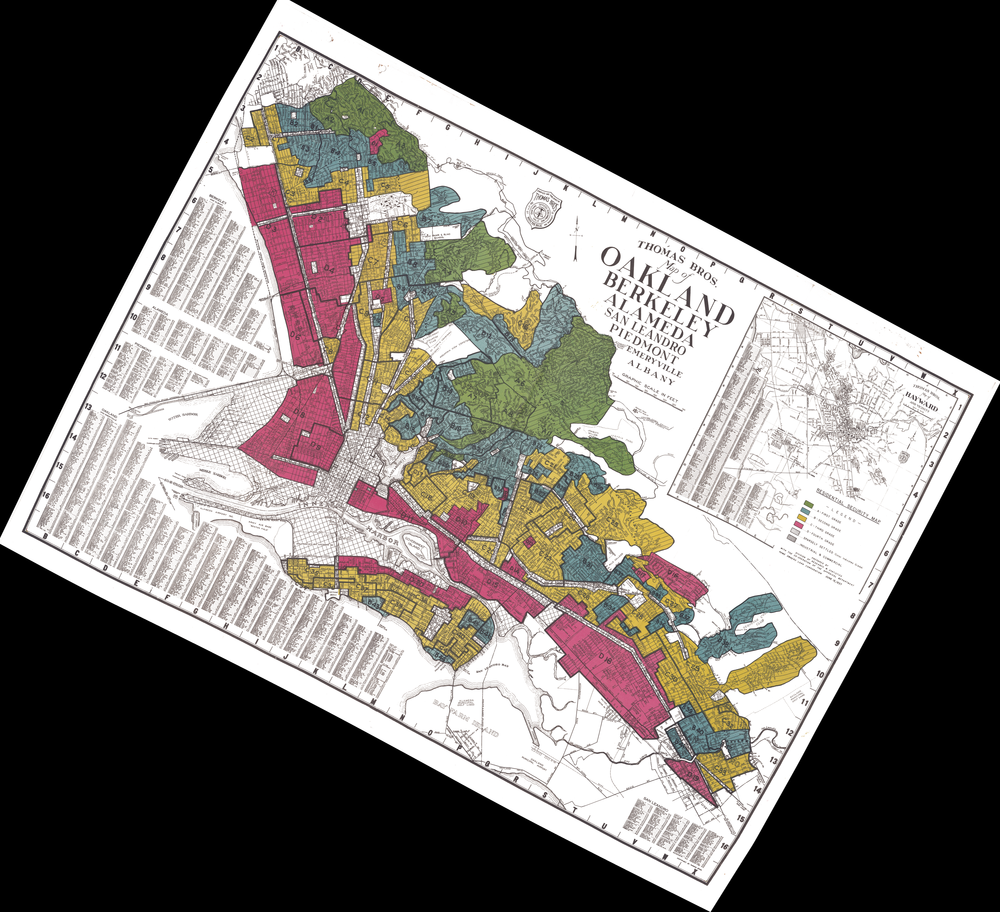

In [24]:
# ============================================================
# OAKLAND 1937 HISTORICAL HOLC MAP
# ORIGINAL GEOTIFF + HOLC GRADES + ACS DEMOGRAPHICS
# INTERACTIVE FOLIUM MAP
# ============================================================

# ------------------------------------------------------------
# 1. IMPORTS
# ------------------------------------------------------------

import os
import io
import base64
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import folium

from PIL import Image
from rasterio.warp import transform_bounds
from folium.features import GeoJsonTooltip
from folium.plugins import Fullscreen

# ------------------------------------------------------------
# 2. FILE PATHS
# ------------------------------------------------------------

raster_path = (
    "/Users/sophiameyers/Documents/GitHub/30-day-mapping/"
    "data/CA_Oakland_1937.tif"
)

output_path = (
    "/Users/sophiameyers/Documents/GitHub/30-day-mapping/"
    "outputs/Oakland_1937_HOLC_Interactive.html"
)

os.makedirs(os.path.dirname(output_path), exist_ok=True)

# ------------------------------------------------------------
# 3. LOAD ORIGINAL HISTORICAL RASTER
# NO REPROJECTION — PRESERVE ORIGINAL ORIENTATION
# ------------------------------------------------------------

print("Loading original historical raster...")

with rasterio.open(raster_path) as src:

    print("Original CRS:", src.crs)
    print("Original dimensions:", src.width, src.height)
    print("Original bounds:", src.bounds)

    # Read original RGB bands
    rgb = src.read([1, 2, 3])

    # Convert to image format
    rgb = np.moveaxis(rgb, 0, -1)

    # Normalize only if the source is not already 8-bit
    if rgb.dtype != np.uint8:

        rgb_min = np.nanpercentile(rgb, 1)
        rgb_max = np.nanpercentile(rgb, 99)

        rgb = np.clip(
            (rgb.astype(float) - rgb_min)
            / (rgb_max - rgb_min)
            * 255,
            0,
            255
        ).astype(np.uint8)

    # Downsample for browser performance
    max_dimension = 3000

    scale = min(
        1,
        max_dimension / max(rgb.shape[0], rgb.shape[1])
    )

    new_width = max(1, int(rgb.shape[1] * scale))
    new_height = max(1, int(rgb.shape[0] * scale))

    historical_pil = Image.fromarray(rgb).resize(
        (new_width, new_height),
        Image.Resampling.LANCZOS
    )

    # Transform original raster bounds to latitude/longitude
    west, south, east, north = transform_bounds(
        src.crs,
        "EPSG:4326",
        *src.bounds
    )

# ------------------------------------------------------------
# 4. CONVERT RASTER TO EMBEDDED PNG
# ------------------------------------------------------------

buffer = io.BytesIO()

historical_pil.save(
    buffer,
    format="PNG",
    optimize=True
)

image_base64 = base64.b64encode(
    buffer.getvalue()
).decode("utf-8")

image_url = "data:image/png;base64," + image_base64

image_bounds = [
    [south, west],
    [north, east]
]

print("Historical image prepared.")
print("Image dimensions:", historical_pil.size)
print("Geographic bounds:", image_bounds)

# ------------------------------------------------------------
# 5. PREPARE HOLC POLYGONS
# ------------------------------------------------------------

print("Preparing HOLC polygons...")

holc_web = holc_map.to_crs("EPSG:4326").copy()

# Remove empty geometries
holc_web = holc_web[
    holc_web.geometry.notna()
    & ~holc_web.geometry.is_empty
].copy()

# ------------------------------------------------------------
# 6. FORMAT DEMOGRAPHIC VARIABLES
# ------------------------------------------------------------

def fmt_number(value):
    if pd.isna(value):
        return "N/A"
    return f"{value:,.0f}"

def fmt_percent(value):
    if pd.isna(value):
        return "N/A"
    return f"{value:.1f}%"

def fmt_currency(value):
    if pd.isna(value):
        return "N/A"
    return f"${value:,.0f}"

# Population and households
holc_web["population_display"] = (
    holc_web["population"].apply(fmt_number)
)

holc_web["households_display"] = (
    holc_web["households"].apply(fmt_number)
)

# Race and ethnicity
holc_web["white_display"] = (
    holc_web["pct_white"].apply(fmt_percent)
)

holc_web["black_display"] = (
    holc_web["pct_black"].apply(fmt_percent)
)

holc_web["asian_display"] = (
    holc_web["pct_asian"].apply(fmt_percent)
)

holc_web["hispanic_display"] = (
    holc_web["pct_hispanic"].apply(fmt_percent)
)

# Income and housing
holc_web["income_display"] = (
    holc_web["weighted_median_income"].apply(fmt_currency)
)

holc_web["home_display"] = (
    holc_web["weighted_median_home_value"].apply(fmt_currency)
)

holc_web["ownership_display"] = (
    holc_web["pct_owner_occupied"].apply(fmt_percent)
)

# Education and poverty
holc_web["college_display"] = (
    holc_web["pct_college_plus"].apply(fmt_percent)
)

holc_web["poverty_display"] = (
    holc_web["pct_poverty"].apply(fmt_percent)
)

# ------------------------------------------------------------
# 7. CREATE FOLIUM MAP
# ------------------------------------------------------------

center_lat = (south + north) / 2
center_lon = (west + east) / 2

m = folium.Map(
    location=[center_lat, center_lon],
    zoom_start=13,
    tiles="CartoDB positron",
    control_scale=True
)

# ------------------------------------------------------------
# 8. ADD HISTORICAL RASTER
# ------------------------------------------------------------

folium.raster_layers.ImageOverlay(
    image=image_url,
    bounds=image_bounds,
    opacity=1,
    name="1937 Oakland Historical Map",
    interactive=False,
    cross_origin=False,
    zindex=1
).add_to(m)

# ------------------------------------------------------------
# 9. HOLC GRADE COLORS
# ------------------------------------------------------------

grade_colors = {
    "A": "#3B8C65",
    "B": "#4D79A8",
    "C": "#E5C34B",
    "D": "#C94B40"
}

def holc_style(feature):

    grade = str(
        feature["properties"].get("grade", "")
    ).upper()

    return {
        "fillColor": grade_colors.get(grade, "#888888"),
        "color": "#252525",
        "weight": 1.1,
        "fillOpacity": 0.32,
        "opacity": 0.95
    }

def holc_highlight(feature):

    return {
        "weight": 3,
        "color": "#FFFFFF",
        "fillOpacity": 0.65,
        "opacity": 1
    }

# ------------------------------------------------------------
# 10. HOVER TOOLTIP
# ------------------------------------------------------------

tooltip_fields = [
    "area_id",
    "grade",
    "population_display",
    "households_display",
    "white_display",
    "black_display",
    "asian_display",
    "hispanic_display",
    "income_display",
    "home_display",
    "ownership_display",
    "college_display",
    "poverty_display"
]

tooltip_aliases = [
    "HOLC Area:",
    "HOLC Grade:",
    "Estimated Population:",
    "Estimated Households:",
    "White, non-Hispanic:",
    "Black, non-Hispanic:",
    "Asian, non-Hispanic:",
    "Hispanic/Latino:",
    "Weighted Average of Tract Median Household Income:",
    "Weighted Average of Tract Median Home Value:",
    "Owner-Occupied Housing:",
    "Bachelor's Degree or Higher:",
    "Below Poverty Level:"
]

holc_layer = folium.GeoJson(
    data=holc_web.to_json(),

    name="HOLC Grades + ACS Demographics",

    style_function=holc_style,

    highlight_function=holc_highlight,

    tooltip=GeoJsonTooltip(
        fields=tooltip_fields,
        aliases=tooltip_aliases,
        localize=False,
        sticky=True,
        labels=True,

        style="""
            background-color: #ffffff;
            color: #222222;
            font-family: Arial, sans-serif;
            font-size: 12px;
            padding: 12px;
            border: 1px solid #555555;
            border-radius: 3px;
        """
    )
)

holc_layer.add_to(m)

# ------------------------------------------------------------
# 11. LEGEND
# ------------------------------------------------------------

legend_html = """
<div style="
position: fixed;
bottom: 35px;
left: 35px;
z-index: 9999;
background: rgba(255,255,255,0.95);
padding: 14px 18px;
border: 1px solid #777;
border-radius: 3px;
font-family: Arial, sans-serif;
font-size: 12px;
color: #222;
">

<div style="font-weight: bold; margin-bottom: 10px;">
1937 HOLC Residential Security Grades
</div>

<div style="margin-bottom: 5px;">
<span style="color:#3B8C65;">&#9632;</span>
A — Best
</div>

<div style="margin-bottom: 5px;">
<span style="color:#4D79A8;">&#9632;</span>
B — Still Desirable
</div>

<div style="margin-bottom: 5px;">
<span style="color:#E5C34B;">&#9632;</span>
C — Definitely Declining
</div>

<div>
<span style="color:#C94B40;">&#9632;</span>
D — Hazardous
</div>

</div>
"""

m.get_root().html.add_child(
    folium.Element(legend_html)
)

# ------------------------------------------------------------
# 12. MAP CONTROLS
# ------------------------------------------------------------

Fullscreen(
    position="topright",
    title="Expand map",
    title_cancel="Exit fullscreen"
).add_to(m)

folium.LayerControl(
    collapsed=False
).add_to(m)

# Fit map to historical raster extent
m.fit_bounds(image_bounds)

# ------------------------------------------------------------
# 13. SAVE INTERACTIVE HTML
# ------------------------------------------------------------

m.save(output_path)

print("\n" + "=" * 55)
print("INTERACTIVE MAP SUCCESSFULLY CREATED")
print("=" * 55)

print("HOLC polygons:", len(holc_web))
print("Historical raster:", historical_pil.size)
print("Output:", output_path)

display(m)

HOLC polygons within image extent: 120
Map saved: /Users/sophiameyers/Documents/GitHub/30-day-mapping/outputs/Oakland_1937_HOLC_Interactive.html
Raster dimensions: (3000, 2736)
HOLC polygons: 120



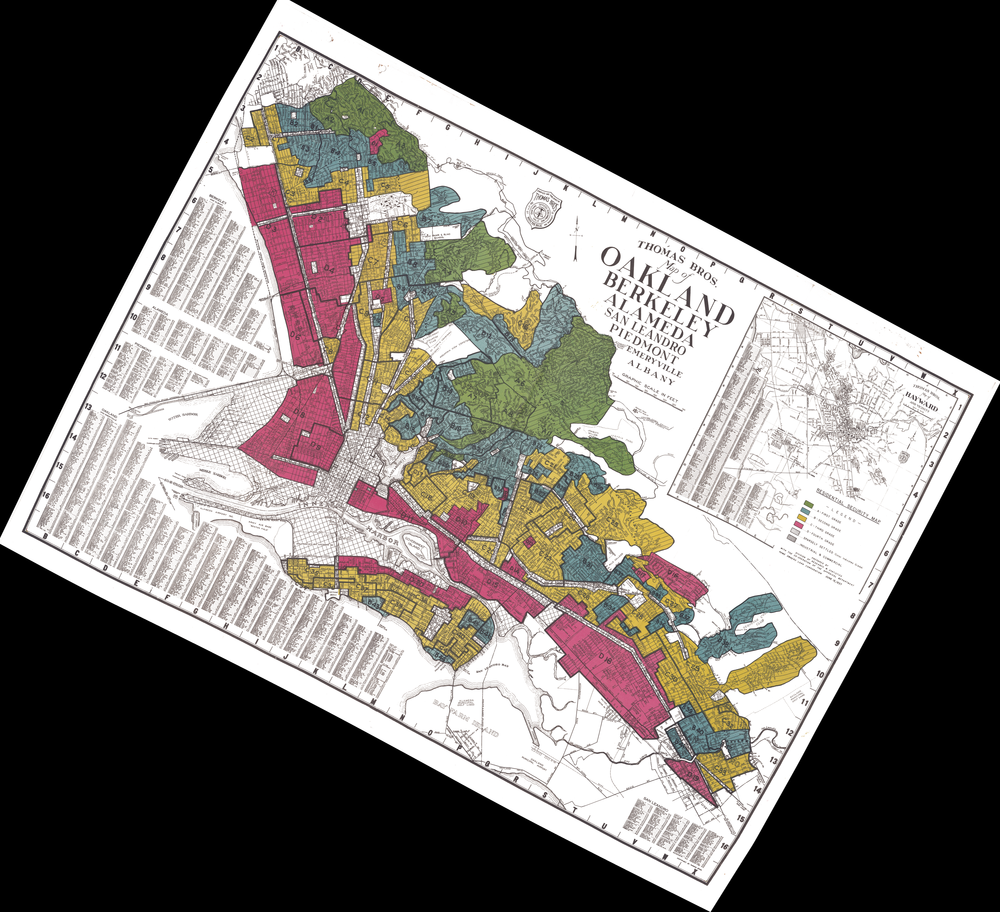

In [26]:
# ============================================================
# OAKLAND 1937 HOLC MAP
# CLIPPED TO HISTORICAL RASTER EXTENT
# GREY BACKGROUND — NO LEGEND — NO LAYER CONTROL
# ============================================================

import os
import io
import base64
import numpy as np
import pandas as pd
import rasterio
import folium

from PIL import Image
from rasterio.warp import transform_bounds
from folium.features import GeoJsonTooltip
from folium.plugins import Fullscreen

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

raster_path = (
    "/Users/sophiameyers/Documents/GitHub/30-day-mapping/"
    "data/CA_Oakland_1937.tif"
)

output_path = (
    "/Users/sophiameyers/Documents/GitHub/30-day-mapping/"
    "outputs/Oakland_1937_HOLC_Interactive.html"
)

os.makedirs(os.path.dirname(output_path), exist_ok=True)

# ------------------------------------------------------------
# 2. LOAD HISTORICAL IMAGE
# ------------------------------------------------------------

with rasterio.open(raster_path) as src:

    rgb = src.read([1, 2, 3])
    rgb = np.moveaxis(rgb, 0, -1)

    if rgb.dtype != np.uint8:
        rgb_min = np.nanpercentile(rgb, 1)
        rgb_max = np.nanpercentile(rgb, 99)

        rgb = np.clip(
            (rgb.astype(float) - rgb_min)
            / (rgb_max - rgb_min) * 255,
            0, 255
        ).astype(np.uint8)

    # Downsample while preserving aspect ratio
    scale = min(
        1,
        3000 / max(rgb.shape[0], rgb.shape[1])
    )

    new_width = max(1, int(rgb.shape[1] * scale))
    new_height = max(1, int(rgb.shape[0] * scale))

    historical_pil = Image.fromarray(rgb).resize(
        (new_width, new_height),
        Image.Resampling.LANCZOS
    )

    # Original raster bounds in WGS84
    west, south, east, north = transform_bounds(
        src.crs,
        "EPSG:4326",
        *src.bounds
    )

# Embed image in HTML
buffer = io.BytesIO()
historical_pil.save(buffer, format="PNG", optimize=True)

image_url = (
    "data:image/png;base64,"
    + base64.b64encode(buffer.getvalue()).decode("utf-8")
)

image_bounds = [
    [south, west],
    [north, east]
]

# ------------------------------------------------------------
# 3. CLIP HOLC POLYGONS TO IMAGE EXTENT
# ------------------------------------------------------------

holc_web = holc_map.to_crs("EPSG:4326").copy()

from shapely.geometry import box

# Clip to exact geographic bounding rectangle of TIFF
image_extent = gpd.GeoDataFrame(
    geometry=[box(west, south, east, north)],
    crs="EPSG:4326"
)

holc_web = gpd.clip(
    holc_web,
    image_extent
)

holc_web = holc_web[
    holc_web.geometry.notna()
    & ~holc_web.geometry.is_empty
].copy()

print("HOLC polygons within image extent:", len(holc_web))

# ------------------------------------------------------------
# 4. FORMAT TOOLTIP DATA
# ------------------------------------------------------------

def fmt_number(x):
    return "N/A" if pd.isna(x) else f"{x:,.0f}"

def fmt_percent(x):
    return "N/A" if pd.isna(x) else f"{x:.1f}%"

def fmt_currency(x):
    return "N/A" if pd.isna(x) else f"${x:,.0f}"

display_columns = {
    "population": "population_display",
    "households": "households_display",
    "pct_white": "white_display",
    "pct_black": "black_display",
    "pct_asian": "asian_display",
    "pct_hispanic": "hispanic_display",
    "weighted_median_income": "income_display",
    "weighted_median_home_value": "home_display",
    "pct_owner_occupied": "ownership_display",
    "pct_college_plus": "college_display",
    "pct_poverty": "poverty_display"
}

for source, target in display_columns.items():

    if "income" in source or "value" in source:
        holc_web[target] = holc_web[source].apply(fmt_currency)

    elif source.startswith("pct_"):
        holc_web[target] = holc_web[source].apply(fmt_percent)

    else:
        holc_web[target] = holc_web[source].apply(fmt_number)

# ------------------------------------------------------------
# 5. CREATE GREY MAP CANVAS
# ------------------------------------------------------------

m = folium.Map(
    location=[
        (south + north) / 2,
        (west + east) / 2
    ],
    zoom_start=13,
    tiles=None,
    control_scale=False,
    prefer_canvas=True
)

# Grey background outside historical image
m.get_root().html.add_child(
    folium.Element("""
    <style>
        html, body {
            background-color: #bdbdbd !important;
            margin: 0;
            padding: 0;
        }

        .folium-map {
            background-color: #bdbdbd !important;
        }

        .leaflet-container {
            background: #bdbdbd !important;
        }

        .leaflet-control-attribution {
            display: none !important;
        }
    </style>
    """)
)

# ------------------------------------------------------------
# 6. ADD HISTORICAL IMAGE
# ------------------------------------------------------------

folium.raster_layers.ImageOverlay(
    image=image_url,
    bounds=image_bounds,
    opacity=1,
    name="1937 Oakland",
    interactive=False,
    zindex=1
).add_to(m)

# ------------------------------------------------------------
# 7. HOLC COLORS
# ------------------------------------------------------------

grade_colors = {
    "A": "#3B8C65",
    "B": "#4D79A8",
    "C": "#E5C34B",
    "D": "#C94B40"
}

def holc_style(feature):

    grade = str(
        feature["properties"].get("grade", "")
    ).upper()

    return {
        "fillColor": grade_colors.get(grade, "#888888"),
        "color": "#252525",
        "weight": 1.1,
        "fillOpacity": 0.32,
        "opacity": 0.95
    }

def holc_highlight(feature):

    return {
        "weight": 3,
        "color": "#FFFFFF",
        "fillOpacity": 0.65
    }

# ------------------------------------------------------------
# 8. DEMOGRAPHIC HOVER TOOLTIP
# ------------------------------------------------------------

tooltip_fields = [
    "area_id",
    "grade",
    "population_display",
    "households_display",
    "white_display",
    "black_display",
    "asian_display",
    "hispanic_display",
    "income_display",
    "home_display",
    "ownership_display",
    "college_display",
    "poverty_display"
]

tooltip_aliases = [
    "HOLC Area:",
    "HOLC Grade:",
    "Estimated Population:",
    "Estimated Households:",
    "White, non-Hispanic:",
    "Black, non-Hispanic:",
    "Asian, non-Hispanic:",
    "Hispanic/Latino:",
    "Weighted Average of Tract Median Income:",
    "Weighted Average of Tract Median Home Value:",
    "Owner-Occupied Housing:",
    "Bachelor's Degree or Higher:",
    "Below Poverty Level:"
]

folium.GeoJson(
    data=holc_web.to_json(),
    style_function=holc_style,
    highlight_function=holc_highlight,
    tooltip=GeoJsonTooltip(
        fields=tooltip_fields,
        aliases=tooltip_aliases,
        sticky=True,
        labels=True,
        style="""
            background-color: white;
            color: #222;
            font-family: Arial, sans-serif;
            font-size: 12px;
            padding: 12px;
            border: 1px solid #555;
        """
    )
).add_to(m)

# ------------------------------------------------------------
# 9. MAP EXTENT
# ------------------------------------------------------------

m.fit_bounds(image_bounds)

# Remove unnecessary padding around image
m.options["fitBoundsOptions"] = {
    "padding": [0, 0]
}

# ------------------------------------------------------------
# 10. SAVE
# ------------------------------------------------------------

m.save(output_path)

print("Map saved:", output_path)
print("Raster dimensions:", historical_pil.size)
print("HOLC polygons:", len(holc_web))

display(m)

Original raster CRS: EPSG:3857
Original raster dimensions: 9590 8748
HOLC polygons inside image extent: 120
Map saved:
/Users/sophiameyers/Documents/GitHub/30-day-mapping/outputs/Oakland_1937_HOLC_Interactive.html



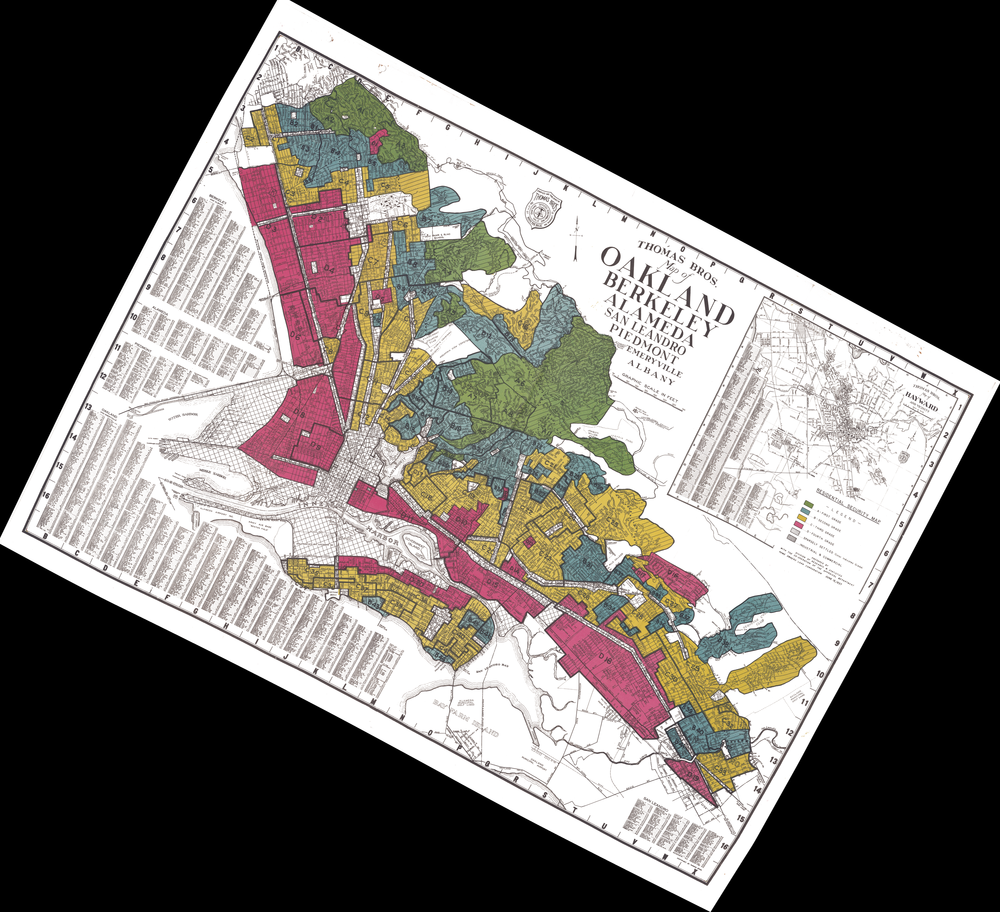

In [28]:
# ============================================================
# OAKLAND 1937 HOLC MAP — FINAL INTERACTIVE MAP
# Original georeferenced TIFF + clipped HOLC polygons
# No basemap, no grey background, no legend
# ============================================================

import os
import io
import base64

import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import folium

from PIL import Image
from rasterio.warp import transform_bounds
from shapely.geometry import box
from folium.features import GeoJsonTooltip
from folium.plugins import Fullscreen


# ------------------------------------------------------------
# 1. FILE PATHS
# ------------------------------------------------------------

raster_path = (
    "/Users/sophiameyers/Documents/GitHub/"
    "30-day-mapping/data/CA_Oakland_1937.tif"
)

output_path = (
    "/Users/sophiameyers/Documents/GitHub/"
    "30-day-mapping/outputs/Oakland_1937_HOLC_Interactive.html"
)

os.makedirs(os.path.dirname(output_path), exist_ok=True)


# ------------------------------------------------------------
# 2. READ ORIGINAL TIFF — DO NOT REPROJECT
# ------------------------------------------------------------

with rasterio.open(raster_path) as src:

    print("Original raster CRS:", src.crs)
    print("Original raster dimensions:", src.width, src.height)

    # Read RGB bands
    rgb = src.read([1, 2, 3])

    # Move bands to final image dimension
    rgb = np.moveaxis(rgb, 0, -1)

    # Normalize only if necessary
    if rgb.dtype != np.uint8:

        rgb = rgb.astype("float32")

        valid = np.isfinite(rgb)

        if valid.any():
            low = np.nanpercentile(rgb[valid], 2)
            high = np.nanpercentile(rgb[valid], 98)

            if high > low:
                rgb = (rgb - low) / (high - low) * 255
            else:
                rgb = np.zeros_like(rgb)

        rgb = np.nan_to_num(rgb, nan=0)
        rgb = np.clip(rgb, 0, 255).astype("uint8")

    # Preserve original proportions while reducing file size
    max_dimension = 3000

    scale = min(
        1,
        max_dimension / max(rgb.shape[0], rgb.shape[1])
    )

    if scale < 1:

        new_width = max(1, int(rgb.shape[1] * scale))
        new_height = max(1, int(rgb.shape[0] * scale))

        image = Image.fromarray(rgb)
        image = image.resize(
            (new_width, new_height),
            Image.Resampling.LANCZOS
        )

        rgb = np.array(image)

    # Convert to PNG for Folium
    image = Image.fromarray(rgb)

    image_buffer = io.BytesIO()
    image.save(image_buffer, format="PNG")

    image_base64 = base64.b64encode(
        image_buffer.getvalue()
    ).decode("utf-8")

    image_url = "data:image/png;base64," + image_base64

    # Transform only the geographic bounds for Leaflet
    west, south, east, north = transform_bounds(
        src.crs,
        "EPSG:4326",
        *src.bounds
    )


# ------------------------------------------------------------
# 3. DEFINE IMAGE EXTENT
# ------------------------------------------------------------

image_extent = gpd.GeoDataFrame(
    geometry=[
        box(west, south, east, north)
    ],
    crs="EPSG:4326"
)

image_bounds = [
    [south, west],
    [north, east]
]


# ------------------------------------------------------------
# 4. CLIP HOLC POLYGONS TO IMAGE EXTENT
# ------------------------------------------------------------

holc_wgs84 = holc_map.to_crs("EPSG:4326").copy()

holc_clipped = gpd.clip(
    holc_wgs84,
    image_extent
)

holc_clipped = holc_clipped[
    ~holc_clipped.geometry.is_empty
].copy()

print("HOLC polygons inside image extent:", len(holc_clipped))


# ------------------------------------------------------------
# 5. PREPARE TOOLTIP ATTRIBUTES
# ------------------------------------------------------------

# Format demographic values for display
def format_number(value):
    if pd.isna(value):
        return "Not available"
    return f"{value:,.0f}"


def format_percent(value):
    if pd.isna(value):
        return "Not available"
    return f"{value:.1f}%"


holc_clipped["Population"] = holc_clipped["population"].apply(
    format_number
)

holc_clipped["White population (%)"] = holc_clipped["pct_white"].apply(
    format_percent
)

holc_clipped["Black population (%)"] = holc_clipped["pct_black"].apply(
    format_percent
)

holc_clipped["Asian population (%)"] = holc_clipped["pct_asian"].apply(
    format_percent
)

holc_clipped["Hispanic population (%)"] = holc_clipped["pct_hispanic"].apply(
    format_percent
)

holc_clipped["College educated (%)"] = holc_clipped["pct_college_plus"].apply(
    format_percent
)

holc_clipped["Below poverty (%)"] = holc_clipped["pct_poverty"].apply(
    format_percent
)

holc_clipped["Owner occupied (%)"] = holc_clipped["pct_owner_occupied"].apply(
    format_percent
)

holc_clipped["Weighted median household income"] = (
    holc_clipped["weighted_median_income"].apply(
        lambda x: "Not available" if pd.isna(x) else f"${x:,.0f}"
    )
)

holc_clipped["Weighted median home value"] = (
    holc_clipped["weighted_median_home_value"].apply(
        lambda x: "Not available" if pd.isna(x) else f"${x:,.0f}"
    )
)


# ------------------------------------------------------------
# 6. HOLC COLORS
# ------------------------------------------------------------

holc_colors = {
    "A": "#4A9B76",
    "B": "#6B8FB8",
    "C": "#E8B84D",
    "D": "#C75B5B"
}


# ------------------------------------------------------------
# 7. CREATE BLACK EXHIBITION-STYLE MAP
# ------------------------------------------------------------

m = folium.Map(
    location=[
        (south + north) / 2,
        (west + east) / 2
    ],
    zoom_start=13,
    tiles=None,
    control_scale=False
)

# Black background and white typography
m.get_root().html.add_child(
    folium.Element("""
    <style>
        html, body {
            margin: 0;
            padding: 0;
            background: #050505 !important;
            overflow: hidden;
        }

        .folium-map {
            background: #050505 !important;
        }

        .leaflet-container {
            background: #050505 !important;
        }

        .map-header {
            position: fixed;
            top: 22px;
            left: 30px;
            z-index: 9999;
            color: white;
            font-family: Helvetica, Arial, sans-serif;
            pointer-events: none;
        }

        .map-header h1 {
            font-size: 23px;
            font-weight: 400;
            letter-spacing: 3px;
            margin: 0;
        }

        .map-header p {
            font-size: 10px;
            letter-spacing: 2px;
            color: #bbbbbb;
            margin-top: 7px;
            text-transform: uppercase;
        }

        .map-frame {
            position: fixed;
            inset: 85px 30px 30px 30px;
            border: 1px solid rgba(255,255,255,0.65);
            z-index: 9998;
            pointer-events: none;
        }
    </style>

    <div class="map-header">
        <h1>OAKLAND, CALIFORNIA</h1>
        <p>HOLC Residential Security Map · 1937</p>
    </div>

    <div class="map-frame"></div>
    """)
)


# ------------------------------------------------------------
# 8. ADD HISTORICAL IMAGE
# ------------------------------------------------------------

folium.raster_layers.ImageOverlay(
    image=image_url,
    bounds=image_bounds,
    opacity=1,
    interactive=False,
    cross_origin=False,
    zindex=1
).add_to(m)


# ------------------------------------------------------------
# 9. ADD HOLC POLYGONS
# ------------------------------------------------------------

folium.GeoJson(
    holc_clipped,

    style_function=lambda feature: {
        "fillColor": holc_colors.get(
            str(feature["properties"].get("grade", "")).upper(),
            "#999999"
        ),
        "color": holc_colors.get(
            str(feature["properties"].get("grade", "")).upper(),
            "#999999"
        ),
        "weight": 1.2,
        "fillOpacity": 0.30,
        "opacity": 0.9
    },

    highlight_function=lambda feature: {
        "weight": 3,
        "color": "#FFFFFF",
        "fillOpacity": 0.55
    },

    tooltip=GeoJsonTooltip(
        fields=[
            "area_id",
            "grade",
            "Population",
            "White population (%)",
            "Black population (%)",
            "Asian population (%)",
            "Hispanic population (%)",
            "College educated (%)",
            "Below poverty (%)",
            "Owner occupied (%)",
            "Weighted median household income",
            "Weighted median home value"
        ],

        aliases=[
            "HOLC Area:",
            "HOLC Grade:",
            "Population:",
            "White population:",
            "Black population:",
            "Asian population:",
            "Hispanic population:",
            "College educated:",
            "Below poverty:",
            "Owner occupied:",
            "Weighted median household income:",
            "Weighted median home value:"
        ],

        sticky=True,
        labels=True
    ),

    smooth_factor=1
).add_to(m)


# ------------------------------------------------------------
# 10. FIT IMAGE TO VIEWER
# ------------------------------------------------------------

m.fit_bounds(image_bounds)

Fullscreen(
    position="topleft",
    title="Expand map",
    title_cancel="Exit fullscreen"
).add_to(m)


# ------------------------------------------------------------
# 11. SAVE
# ------------------------------------------------------------

m.save(output_path)

print("Map saved:")
print(output_path)

display(m)